# `Байесовские методы в анализе данных.`

## `Занятие 04: Методы сэмплирования`

Источники:

- [GitHub курса](https://github.com/bmml-team/bmml_ftda)

---

In [1]:
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
from torch.distributions import Normal, Exponential, Cauchy, MixtureSameFamily, Categorical

In [2]:
def vis_sample(dist, samples, use_log=False, ax=None, title=None):
    a, b = torch.quantile(samples, torch.tensor([0.001, 0.999]))
    print(f"Квантили {a:0.3f}, {b:0.3f}")
    grid = torch.linspace(a, b, 1000)
    
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    
    ax.hist(samples, bins=100, density=True, alpha=0.5, label="Гистограмма распределения")
    ax.plot(grid, dist.log_prob(grid).exp(), label="Плотность распределения")

    ax.grid()
    if title is None:
        ax.set_title(f"Распределение {repr(dist)}")
    else:
        ax.set_title(title)
    ax.set_xlabel("Носитель")
    ax.set_ylabel("Вероятность")
    if use_log:
        ax.set_yscale('log')
    ax.legend()
    

## Метод обратной функции

In [3]:
torch.manual_seed(42)
N = 10000
xi = torch.rand(N)

Квантили 0.002, 6.290


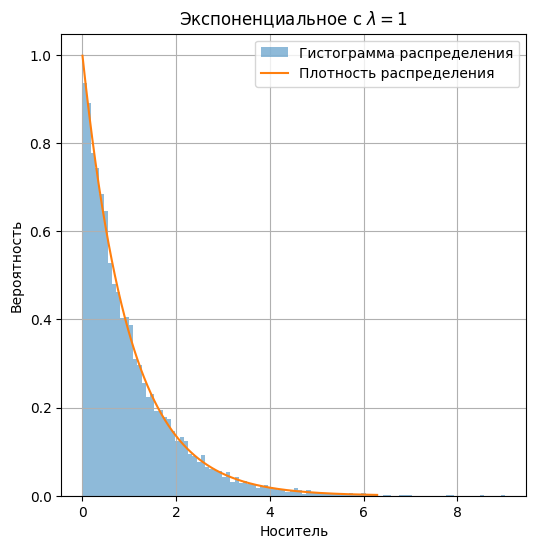

In [4]:
dist = Exponential(torch.tensor([1.]))
vis_sample(dist, dist.icdf(xi), title=r"Экспоненциальное с $\lambda = 1$")

In [5]:
torch.manual_seed(42)
N = 100000
xi = torch.rand(N)

Квантили -282.248, 318.320


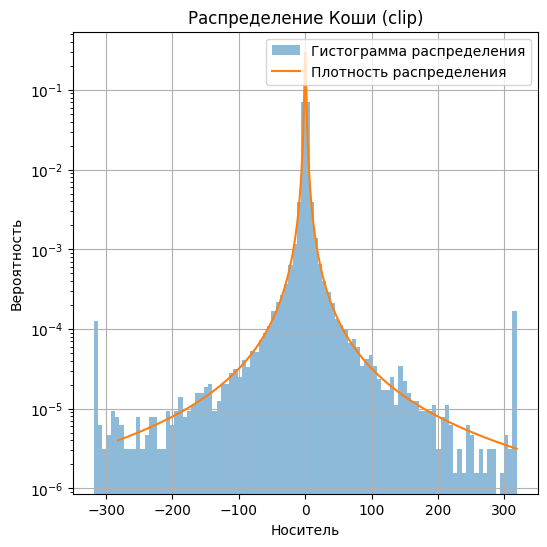

In [6]:
dist = Cauchy(torch.tensor([0.0]), torch.tensor([1.]))

vis_sample(dist, dist.icdf(xi.clip(1e-3, 1 - 1e-3)), use_log=True, title="Распределение Коши (clip)")

Квантили -282.248, 324.628


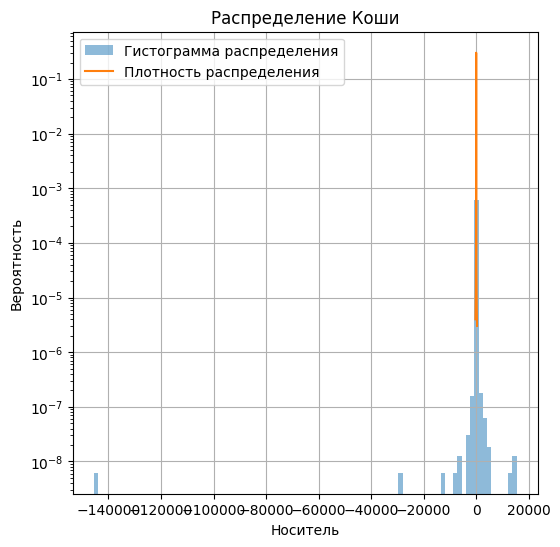

In [7]:
vis_sample(dist, dist.icdf(xi), use_log=True, title="Распределение Коши")

## Метод Метрополиса-Хастингса

In [8]:
torch.manual_seed(42)
w1, w2 = 0.3, 0.7

d = Normal(torch.tensor([3., -3.]), torch.tensor([1., 0.5]))
c = Categorical(torch.tensor([w1, w2]))

dist = MixtureSameFamily(c, d)
samples = dist.sample((N,)).flatten()

Квантили -4.481, 5.708


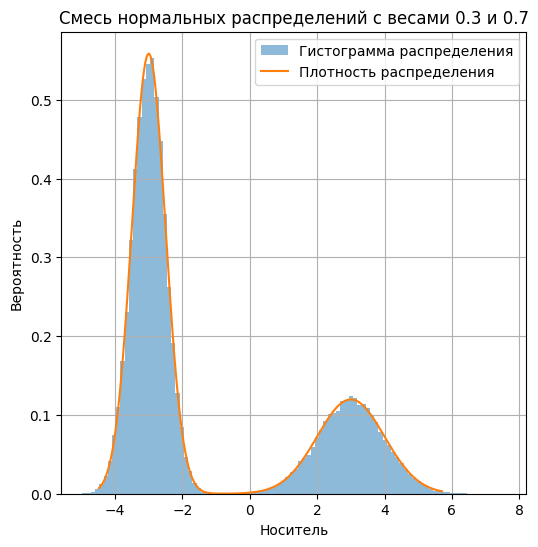

In [9]:
vis_sample(dist, samples, title=f"Смесь нормальных распределений с весами {w1} и {w2}")

In [10]:
def metropolis_hastings(x_init, logprob, trans, n_iters=20000, seed=42):
    torch.manual_seed(seed)
    history = [x_init.item()]
    A_history = [0]
    accept_history = [0]
    
    for i in tqdm(range(n_iters)):
        x = torch.tensor(history[-1])
        trans_x = trans(x) # r(\cdot | x )
        x_new = trans_x.sample() # x' ~ r(x' | x )
        trans_x_new = trans(x_new) # r(\cdot | x' )
        
        log_A = logprob(x_new) + trans_x_new.log_prob(x) - logprob(x) - trans_x.log_prob(x_new)
        A = log_A.exp()
        A = torch.clip(A, None, 1.).item() # min(1, \frac{p(x') r(x | x')}{p(x) r(x' | x )})
        A_history.append(A)
    
        xi = torch.rand(1)   # xi ~ U[0, 1]
        
        # flag ~ Bern(A(x, x'))
        if xi <= A:         # xi <= A(x, x')
            history.append(x_new.item())
            accept_history.append(1)
        else:               # xi > A(x, x')
            history.append(x.item())
            accept_history.append(0)
            
    return torch.tensor(history), torch.tensor(A_history), torch.tensor(accept_history)

def vis_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)

    vis_sample(dist, history, title="Распределение history", ax=ax[0])
    vis_sample(dist, history[-2000:], title="Распределение history[-2000:]", ax=ax[1])
    ax[1].set_ylabel("")
    plt.tight_layout()
    plt.show()

In [11]:
x_init = torch.tensor([0.])
prob = lambda x: dist.log_prob(x)
trans = lambda x: Normal(torch.tensor([x]), torch.tensor([1]))

In [12]:
history, A_history, accept_history = metropolis_hastings(x_init, prob, trans, seed=42)

100%|█████████████████████████████████████████████| 20000/20000 [00:09<00:00, 2181.52it/s]


Квантили -4.529, 5.270
Квантили -4.292, -1.495


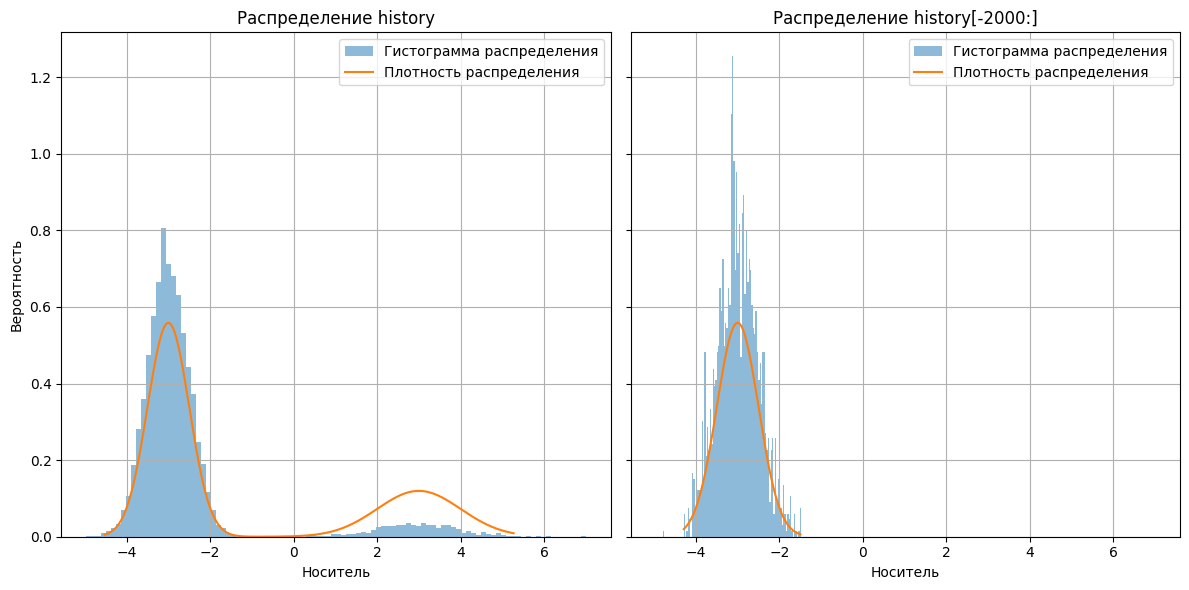

In [13]:
vis_history(history)

100%|█████████████████████████████████████████████| 20000/20000 [00:09<00:00, 2083.47it/s]


Квантили -4.458, 5.442
Квантили -4.478, -1.663


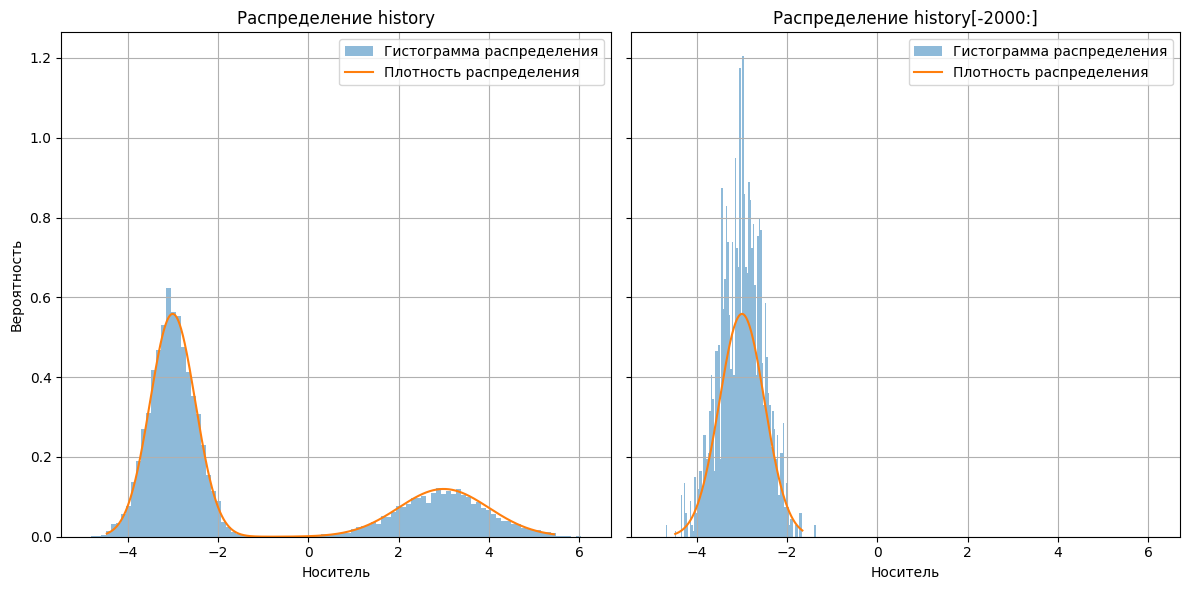

In [14]:
history, A_history, accept_history = metropolis_hastings(x_init, prob, trans, seed=0)
vis_history(history)

100%|█████████████████████████████████████████████| 20000/20000 [00:09<00:00, 2159.80it/s]


Квантили -4.397, 5.739
Квантили 0.049, 6.039


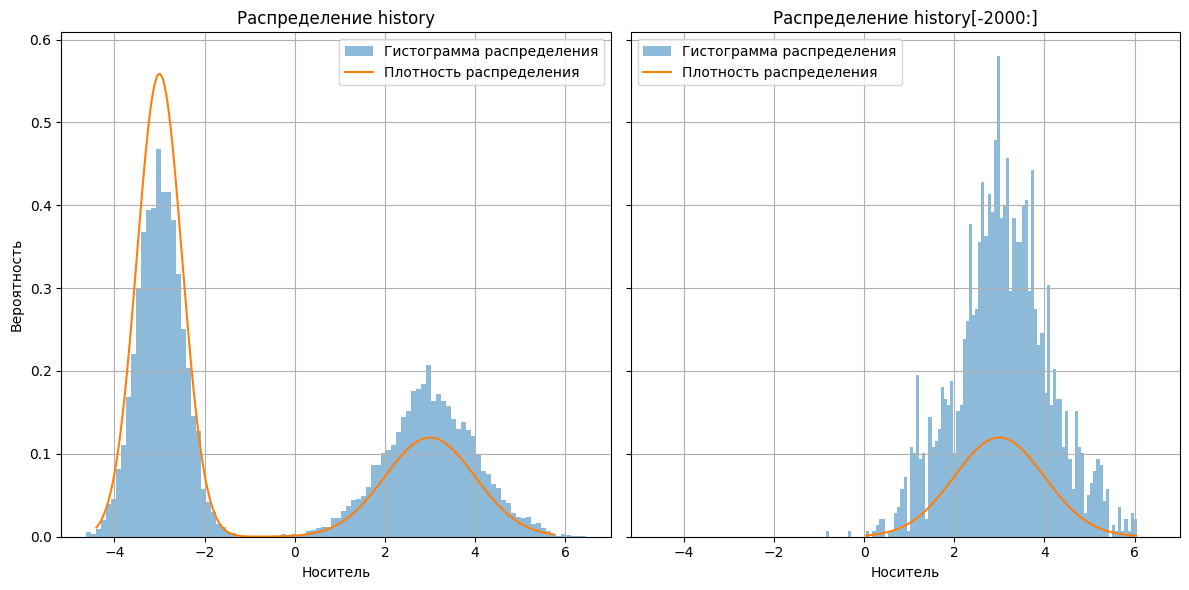

In [15]:
history, A_history, accept_history = metropolis_hastings(x_init, prob, trans, seed=4)
vis_history(history)

Из графиков выше, что соседние сэмплы из марковской цепи сильно скоррелированы (находятся в одной моде).

Если в качестве переходной вероятности мы возьмем "плохое" распределение, то это заметно повлияет на качество.

In [16]:
trans = lambda x: Normal(torch.tensor([0.]), torch.tensor([1]))

100%|█████████████████████████████████████████████| 20000/20000 [00:09<00:00, 2117.65it/s]


Квантили -4.432, 3.865
Квантили -4.132, 2.804


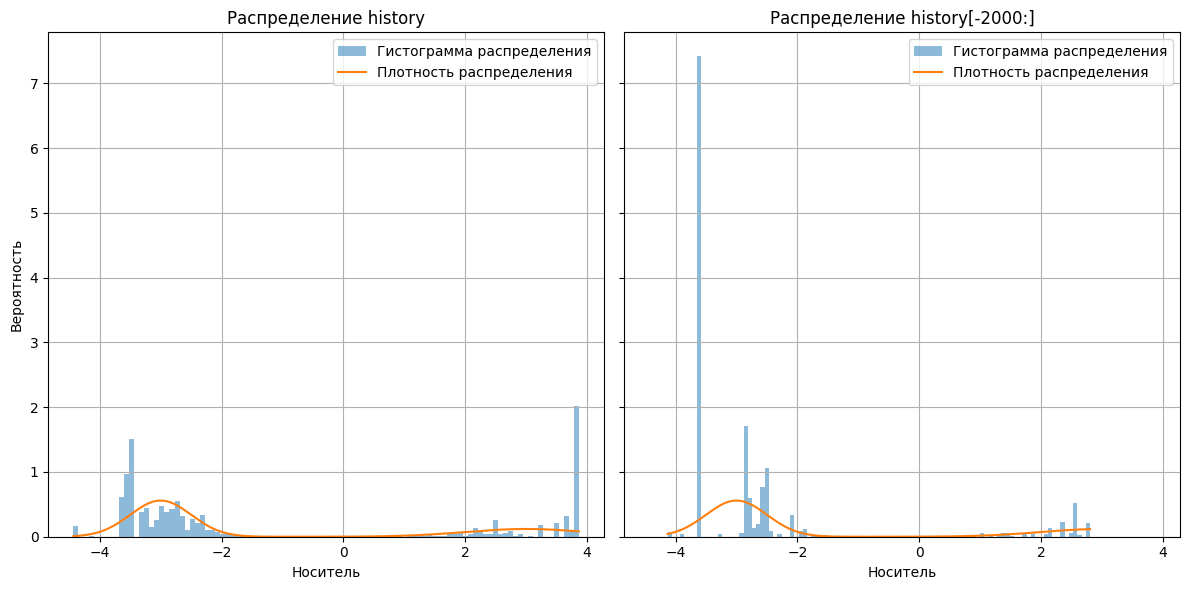

In [17]:
history, A_history, accept_history = metropolis_hastings(x_init, prob, trans, seed=42)
vis_history(history)

Если возьмем распределение с маленькой дисперсией, то будем чаще сэмплировать из одной моды.

In [18]:
trans = lambda x: Normal(torch.tensor([x]), torch.tensor([0.2]))

100%|█████████████████████████████████████████████| 20000/20000 [00:09<00:00, 2156.09it/s]


Квантили -0.197, 5.539
Квантили 0.677, 5.412


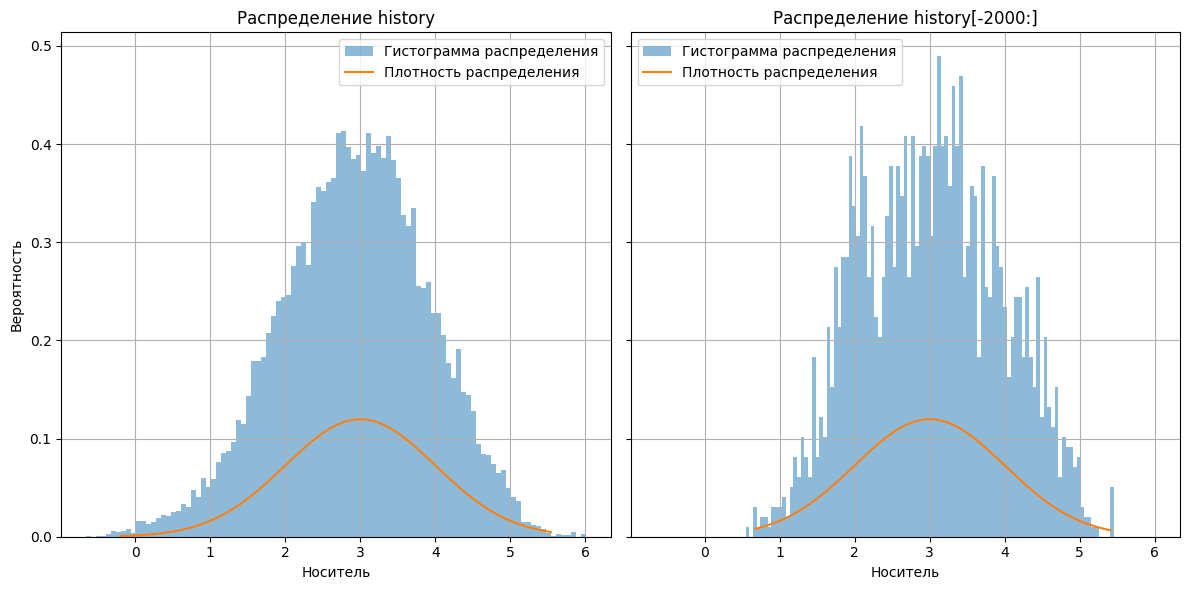

In [19]:
history, A_history, accept_history = metropolis_hastings(x_init, prob, trans, seed=42)
vis_history(history)